# ⚛️ Proyecto IA-Gen: Asistente Experto en Física Nuclear y de Partículas
**Tecnologías:** Google Gemini (`gemini-3.5-flash-lite` / `gemini-embedding-2`), ChromaDB, LangChain, LangGraph.

Este notebook implementa un agente RAG condicional con memoria conversacional especializado en Física Nuclear y de Partículas a partir de los apuntes del curso.

## 0. Configuración del Entorno y Librerías

Se importan los módulos estándar de Python, dependencias de LangChain, componentes de Gemini y LangGraph necesarios para la ejecución del agente.

In [1]:
# 1. Instalación de dependencias necesarias (ejecutar si es necesario)
# !pip install -q langchain langchain-core langchain-community langchain-google-genai langchain-huggingface langchain-chroma langchain-text-splitters langgraph chromadb pydantic pypdf python-dotenv sentence-transformers ipywidgets

# Módulos estándar de Python para tipado, sistema operativo, expresiones regulares y control de tiempo/asincronía
import os
import re
import time
import asyncio
from pathlib import Path
from typing import TypedDict, Annotated, Sequence, Literal

# Carga y gestión de variables de entorno desde el archivo .env
from dotenv import load_dotenv

# Componentes de interfaz interactiva con widgets y visualización en Jupyter Notebook
import ipywidgets as widgets
from IPython.display import display, Image

# Componentes esenciales de LangChain (tipos de mensajes, decorador de herramientas y ejecución)
from langchain_core.messages import (
    BaseMessage,
    HumanMessage,
    AIMessage,
    SystemMessage,
    ToolMessage,
    RemoveMessage,
)
from langchain_core.tools import tool
from langchain_core.runnables import RunnableLambda

# Integraciones de Modelos de Lenguaje (LLMs) y Embeddings (Google Gemini y HuggingFace)
from langchain_google_genai import ChatGoogleGenerativeAI, GoogleGenerativeAIEmbeddings
from langchain_huggingface import HuggingFaceEmbeddings

# Ingesta de documentos PDF, troceado adaptativo de texto e indexación en base vectorial ChromaDB
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_chroma import Chroma

# Componentes de LangGraph para orquestación de agentes basados en grafos de estado y memoria conversacional
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver


print("✅ Librerías e importaciones cargadas correctamente.")

C:\Users\Pablo\AppData\Local\Temp\ipykernel_21892\4172357610.py:36: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


✅ Librerías e importaciones cargadas correctamente.


In [2]:
# Cargar variables de entorno desde el archivo .env
load_dotenv()

# Obtención de la clave API de Gemini
api_key = os.getenv("GEMINI_API_KEY")

print("✅ Clave API de Google Gemini configurada con éxito.")

✅ Clave API de Google Gemini configurada con éxito.


---

## 📑 Índice de Contenidos

1. [Ingesta, Troceado (Chunking) e Indexación en ChromaDB](#1-ingesta-troceado-chunking-e-indexación-en-chromadb)
   - [1.1. Indexación en la Nube con GoogleGenerativeAIEmbeddings](#11-indexación-en-la-nube-con-googlegenerativeaiembeddings)
   - [1.2. Indexación Local con HuggingFaceEmbeddings](#12-indexación-local-con-huggingfaceembeddings)
   - [1.3. Verificación Rápida de Recuperación Comparativa (Retrieval)](#13-verificación-rápida-de-recuperación-comparativa-retrieval)
2. [Herramientas del Agente y System Prompt](#2-herramientas-del-agente-y-system-prompt)
   - [2.1. Selección Interactiva del Retriever Activo](#21-selección-interactiva-del-retriever-activo)
3. [Orquestación del Agente en LangGraph con RAG Condicional y Memoria](#3-orquestación-del-agente-en-langgraph-con-rag-condicional-y-memoria)
   - [3.1. Modelos Base, Fallbacks Nativos y Esquema de Estado](#31-modelos-base-fallbacks-nativos-y-esquema-de-estado)
   - [3.2. Nodos de Ejecución, Router de Complejidad y Validador de Salida](#32-nodos-de-ejecución-router-de-complejidad-y-validador-de-salida)
   - [3.3. Ensamblado del Grafo, Compilación y Diagrama de Flujo (Mermaid)](#33-ensamblado-del-grafo-compilación-y-diagrama-de-flujo-mermaid)
   - [Anotación sobre el Diagrama de Flujo](#anotación-sobre-el-diagrama-de-flujo)
4. [Celda Interactiva y Pruebas Documentadas](#4-celda-interactiva-y-pruebas-documentadas)
   - [Conclusiones de los Resultados y Medidas de Seguridad](#conclusiones-de-los-resultados-y-medidas-de-seguridad)

---

## 1. Ingesta, Troceado (Chunking) e Indexación en ChromaDB

En esta sección se realiza el procesamiento de los documentos y la construcción de la base de conocimiento vectorial mediante una **estrategia dual de embeddings**.

### 1.1. Indexación en la Nube con GoogleGenerativeAIEmbeddings

Procesamiento e indexación de la documentación técnica empleando los modelos de embeddings de Google Gemini:

* **Carga de Documentos:** Ingesta de los archivos de apuntes de Física Nuclear y de Partículas (`fnp2.pdf` y `apuntes_nuclear_corregidos.pdf`) ubicados en `../documentation` mediante `PyPDFLoader`.
* **Segmentación de Texto (Chunking):** Fragmentación con `RecursiveCharacterTextSplitter` (`chunk_size=900`, `chunk_overlap=150`) para asegurar la continuidad del contexto conceptual y preservar las fórmulas en notación LaTeX.
* **Modelo de Embeddings:** `models/gemini-embedding-2` (3072 dimensiones), persistido en disco en `../chroma_db/chroma_db_fisica_api`.
* **Control de Cuota y Lotes:** Indexación por bloques (`batch_size=20`), pausas de seguridad de 3 segundos entre lotes y bucle de reintento automático de 60 segundos ante errores de límite de cuota (`429` / `RESOURCE_EXHAUSTED`).
* **Persistencia Cauta:** Verificación de existencia en disco (`db_path_api.exists() and any(db_path_api.iterdir())`) para recargar la base de forma instantánea sin consumir llamadas a la API.

In [3]:
# 1. Rutas y configuración de embeddings
db_path_api = Path("../chroma_db/chroma_db_fisica_api")

embeddings = GoogleGenerativeAIEmbeddings(
    model="models/gemini-embedding-2",
    task_type="retrieval_document"
)

# 2. Comprobar si la base vectorial ya existe y no está vacía
if db_path_api.exists() and any(db_path_api.iterdir()):
    print("📂 La base vectorial ya existe en disco. Cargándola directamente (0 llamadas a la API)...")
    vectorstore = Chroma(
        persist_directory=str(db_path_api),
        embedding_function=embeddings,
        collection_name="apuntes_fisica_nuclear"
    )
else:
    print("⚙️ Base vectorial no encontrada. Iniciando la ingesta de PDFs y creación por lotes...")
    
    # Carga de PDFs
    pdf_dir = Path("../documentation")
    pdf_paths = ["fnp2.pdf", "apuntes_nuclear_corregidos.pdf"]
    documentos_totales = []

    for path in pdf_paths:
        full_pdf_path = pdf_dir / path
        if full_pdf_path.exists():
            loader = PyPDFLoader(str(full_pdf_path))
            docs = loader.load()
            documentos_totales.extend(docs)
            print(f"📄 Cargado: {path} ({len(docs)} páginas)")

    if not documentos_totales:
        raise ValueError("❌ No se cargó ningún documento. Revisa las rutas de los archivos PDF.")

    # Troceado de texto
    text_splitter = RecursiveCharacterTextSplitter(
        chunk_size=900,
        chunk_overlap=150,
        separators=["\n\n", "\n", " ", ""]
    )
    chunks = text_splitter.split_documents(documentos_totales)
    print(f"✂️ Total de chunks generados: {len(chunks)}")

    # Indexación por lotes con control de cuota
    batch_size = 20
    vectorstore = None

    print(f"⏳ Indexando {len(chunks)} chunks mediante la API de Gemini...")
    for i in range(0, len(chunks), batch_size):
        batch = chunks[i:i + batch_size]
        completado = False
        
        while not completado:
            try:
                if vectorstore is None:
                    vectorstore = Chroma.from_documents(
                        documents=batch,
                        embedding=embeddings,
                        collection_name="apuntes_fisica_nuclear",
                        persist_directory=str(db_path_api)
                    )
                else:
                    vectorstore.add_documents(documents=batch)
                
                completado = True
                print(f"  └─ Procesados {min(i + batch_size, len(chunks))}/{len(chunks)} chunks")
                time.sleep(3)
                
            except Exception as e:
                if "429" in str(e) or "RESOURCE_EXHAUSTED" in str(e):
                    print("⚠️ Límite de API (429) alcanzado. Esperando 60 segundos a que la cuota se reinicie...")
                    time.sleep(60)
                else:
                    raise e

# 3. Crear el retriever a partir del vectorstore cargado o creado
retriever_api = vectorstore.as_retriever(search_kwargs={"k": 4})
print("✅ Base vectorial ChromaDB lista para realizar búsquedas.")

📂 La base vectorial ya existe en disco. Cargándola directamente (0 llamadas a la API)...
✅ Base vectorial ChromaDB lista para realizar búsquedas.


### 1.2. Indexación Local con HuggingFaceEmbeddings

Generación alternativa de vectores en entorno local para garantizar ejecuciones inmediatas y sin dependencia de cuotas de red:

* **Carga y Troceado:** Aplicación de los mismos parámetros de segmentación (`chunk_size=900`, `chunk_overlap=150`) sobre el corpus documental de `../documentation`.
* **Modelo de Embeddings:** `sentence-transformers/all-MiniLM-L6-v2` (384 dimensiones), persistido localmente en `../chroma_db/chroma_db_fisica_HF`.
* **Ventajas Operativas:** Procesamiento 100% local en CPU/GPU, ejecuciones instantáneas y cero restricciones de llamadas por minuto.
* **Persistencia Cauta:** Control de presencia previa en disco para evitar re-indexaciones innecesarias si los vectores ya han sido generados.

In [4]:
# 1. Configuración de la ruta y modelo de embeddings locales
db_path_HF = Path("../chroma_db/chroma_db_fisica_HF")

embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")

# 2. Comprobar si la base vectorial ya existe en disco y contiene datos
if db_path_HF.exists() and any(db_path_HF.iterdir()):
    print("📂 La base vectorial local (HuggingFace) ya existe en disco. Cargándola directamente...")
    vectorstore = Chroma(
        persist_directory=str(db_path_HF),
        embedding_function=embeddings,
        collection_name="apuntes_fisica_nuclear"
    )
else:
    print("⚙️ Base vectorial no encontrada. Cargar PDFs, realizar chunking y crear embeddings...")
    
    # Carga de documentos PDF
    pdf_dir = Path("../documentation")
    pdf_paths = ["fnp2.pdf", "apuntes_nuclear_corregidos.pdf"]
    
    documentos_totales = []
    for path in pdf_paths:
        full_pdf_path = pdf_dir / path
        if full_pdf_path.exists():
            loader = PyPDFLoader(str(full_pdf_path))
            docs = loader.load()
            documentos_totales.extend(docs)
            print(f"📄 Cargado: {path} ({len(docs)} páginas)")

    if not documentos_totales:
        raise ValueError("❌ No se cargó ningún documento. Revisa las rutas.")

    # Troceado de texto
    text_splitter = RecursiveCharacterTextSplitter(
        chunk_size=900,
        chunk_overlap=150,
        separators=["\n\n", "\n", " ", ""]
    )
    chunks = text_splitter.split_documents(documentos_totales)
    print(f"✂️ Total de chunks generados: {len(chunks)}")

    # Indexación vectorial en disco
    print("⏳ Generando embeddings en local...")
    vectorstore = Chroma.from_documents(
        documents=chunks,
        embedding=embeddings,
        collection_name="apuntes_fisica_nuclear",
        persist_directory=str(db_path_HF)
    )

# 3. Crear el retriever a partir de la base vectorial
retriever_hf = vectorstore.as_retriever(search_kwargs={"k": 4})
print("✅ Base vectorial ChromaDB (HuggingFace) lista para realizar búsquedas.")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

📂 La base vectorial local (HuggingFace) ya existe en disco. Cargándola directamente...
✅ Base vectorial ChromaDB (HuggingFace) lista para realizar búsquedas.


### 1.3. Verificación Rápida de Recuperación Comparativa (Retrieval)

Comprobación simultánea sobre ambas bases vectoriales para validar la calidad de búsqueda y comparar el comportamiento semántico entre ambos espacios vectoriales:

* **Consulta Unificada de Prueba:** Invocación simultánea a los retrievers con los términos `"leptones y hadrones"`.
* **Diferenciación Visual:** Presentación separada de los resultados del modelo local de HuggingFace (384 dimensiones) y del modelo en la nube de Gemini API (3072 dimensiones).
* **Inspección de Contenido:** Recuperación de los $k=4$ fragmentos más relevantes y visualización de los primeros 200 caracteres de cada uno para verificar la procedencia del texto.

In [5]:
# Consulta de prueba unificada
consulta = "leptones y hadrones"

print("=" * 70)
print(f"🔍 PRUEBA DE RECUPERACIÓN COMPARATIVA: '{consulta}'")
print("=" * 70)

# 1. Recuperación con HuggingFace (Local - 384 dims)
docs_hf = retriever_hf.invoke(consulta)
print(f"\n🤗 HUGGINGFACE EMBEDDINGS (`all-MiniLM-L6-v2` - 384 dims)")
print(f"Número de fragmentos recuperados: {len(docs_hf)}\n")
for i, doc in enumerate(docs_hf, 1):
    print(f"--- Fragmento {i} (HuggingFace) ---")
    print(f"{doc.page_content[:200].strip()}...\n")

print("-" * 70)

# 2. Recuperación con Gemini (API - 3072 dims)
docs_gemini = retriever_api.invoke(consulta)
print(f"\n♊ GEMINI EMBEDDINGS (`gemini-embedding-2` - 3072 dims)")
print(f"Número de fragmentos recuperados: {len(docs_gemini)}\n")
for i, doc in enumerate(docs_gemini, 1):
    print(f"--- Fragmento {i} (Gemini API) ---")
    print(f"{doc.page_content[:200].strip()}...\n")

🔍 PRUEBA DE RECUPERACIÓN COMPARATIVA: 'leptones y hadrones'



🤗 HUGGINGFACE EMBEDDINGS (`all-MiniLM-L6-v2` - 384 dims)
Número de fragmentos recuperados: 4

--- Fragmento 1 (HuggingFace) ---
que dan hadrones pero no podemos distinguirlos. De modo que tenemos 5 procesos distinguibles:
los de leptones cargados, los invisibles para los neutrinos y los de hadrones para los quarks. Las
probabi...

--- Fragmento 2 (HuggingFace) ---
VI
Hadrones y quarks
15 Números cuánticos adicionales
Tras el descubrimiento del leptón tau, τ− y teniendo en cuenta el resto de leptones (electrones, muones y
neutrinos) y sus respectivos antileptone...

--- Fragmento 3 (HuggingFace) ---
el mismo número de quarks que de antiquarks (mínimo dos). Toda la miríada de hadrones se simplica
enormemente si se toman los quarks como partículas elementales, ya que
• Los bariones están constitui...

--- Fragmento 4 (HuggingFace) ---
10.Inciso algebr´ aico 97
10.1. Grupo SU(2) . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . 97
10.2. Grupo SU(3) . . . . . . .

## 2. Herramientas del Agente y System Prompt

Implementamos una función de fábrica (`crear_herramientas_fisica`) que genera de forma modular un conjunto dual de herramientas `@tool` (`buscar_apuntes_fisica` para teoría general y `buscar_formulas_y_ecuaciones` para expresiones matemáticas) desacopladas del *retriever* concreto (`Gemini API` o `HuggingFace`). Además, configuramos el `SYSTEM_PROMPT` que acota el comportamiento del modelo, imponiendo el uso obligatorio de notación LaTeX y rigurosidad conceptual.

In [6]:
# 1. Herramienta de recuperación RAG
def crear_herramientas_fisica(retriever_instancia):
    
    @tool
    def buscar_apuntes_fisica(consulta: str) -> str:
        """Utiliza esta herramienta para buscar teoría general, definiciones conceptuales y explicaciones cualitativas en los apuntes de física."""
        docs = retriever_instancia.invoke(consulta)
        if not docs:
            return "No se encontró información."
        return "\n\n---\n\n".join([doc.page_content for doc in docs])

    @tool
    def buscar_formulas_y_ecuaciones(concepto: str) -> str:
        """Utiliza esta herramienta SIEMPRE que el usuario solicite fórmulas matemáticas, ecuaciones semiempíricas, expresiones algebraicas o constantes numéricas."""
        docs = retriever_instancia.invoke(f"fórmula ecuación {concepto}")
        if not docs:
            return "No se encontraron fórmulas específicas."
        return "\n\n---\n\n".join([doc.page_content for doc in docs])

    return [buscar_apuntes_fisica, buscar_formulas_y_ecuaciones]

# Instanciación
herramientas_rag_api = crear_herramientas_fisica(retriever_api)
herramientas_rag_hf = crear_herramientas_fisica(retriever_hf)

# 2. Definición del System Prompt con guardarraíles y formato LaTeX
SYSTEM_PROMPT = """Eres un Tutor Experto en Física Nuclear y de Partículas Subatómicas.
Tu objetivo es responder a las dudas teóricas, matemáticas y conceptuales con rigor académico.

REGLAS DE ACTUACIÓN:
1. FORMALISMO MATEMÁTICO: Utiliza notación LaTeX formal para magnitudes, símbolos y fórmulas físicas (ej. $E=mc^2$, $\\beta^-$, $^{235}_{92}\\text{U}$). En respuestas conceptuales o breves, limita el uso de LaTeX a los símbolos necesarios sin incluir desarrollos matemáticos no solicitados.
2. USO DE HERRAMIENTAS: Utiliza 'buscar_apuntes_fisica' para teoría general y 'buscar_formulas_y_ecuaciones' cuando la consulta requiera expresiones matemáticas o valores numéricos concretos.
3. GUARDARRAÍLES Y LÍMITES: Si la pregunta está fuera del dominio de la Física o no se encuentra en la base de conocimiento, indícalo educadamente sin inventar información.
4. TONO: Riguroso, pedagógico, claro y estructurado.
"""

print("✅ Herramienta RAG y System Prompt configurados.")

✅ Herramienta RAG y System Prompt configurados.


### 2.1. Selección Interactiva del Retriever Activo

Mecanismo asíncrono interactivo con control de tiempo de espera (*timeout* de 30 segundos) mediante `ipywidgets` y `asyncio` que permite seleccionar dinámicamente en tiempo de ejecución la base vectorial activa (`Gemini API` o `HuggingFace Local`):

In [7]:
# Selección interactiva del retriever/embeddings (Asíncrono)
print("Selecciona el modelo de embeddings con el que deseas trabajar:")
print("1. Gemini API (gemini-embedding-2)")
print("2. HuggingFace Local (all-MiniLM-L6-v2)")

async def solicitar_opcion_con_timeout(timeout: int = 30) -> str:
    print(f"\n⏳ Tienes {timeout} segundos para seleccionar. Si no ingresas nada, se elegirá HuggingFace Local por defecto.")
    
    radio = widgets.RadioButtons(
        options=[('1. Gemini API (gemini-embedding-2)', '1'), ('2. HuggingFace Local (all-MiniLM-L6-v2)', '2')],
        value='2',
        description='Opción:'
    )
    boton = widgets.Button(description="Confirmar", button_style="primary", icon="check")
    
    confirmado = False
    
    def al_confirmar(b):
        nonlocal confirmado
        confirmado = True
        
    boton.on_click(al_confirmar)
    display(widgets.VBox([radio, boton]))
    
    # Bucle asíncrono: cede el control al event loop para procesar la interacción al instante
    for _ in range(int(timeout * 10)):
        if confirmado:
            break
        await asyncio.sleep(0.1)
        
    radio.disabled = True
    boton.disabled = True
    
    if confirmado:
        # print(f"\n✅ Opción {radio.value} confirmada.")
        return radio.value
    else:
        print(f"⏰ Tiempo de espera agotado ({timeout}s).")
        return "2"

# Ejecución asíncrona directa a nivel de celda en Jupyter Notebook
opcion = await solicitar_opcion_con_timeout(timeout=30)

if opcion == "2":
    herramientas_activas = herramientas_rag_hf
    print("\n✅ Herramientas cargadas usando retriever de HuggingFace (Local).")
else:
    herramientas_activas = herramientas_rag_api
    print("\n✅ Herramientas cargadas usando retriever de Gemini (API).")

mapa_herramientas = {h.name: h for h in herramientas_activas}

Selecciona el modelo de embeddings con el que deseas trabajar:
1. Gemini API (gemini-embedding-2)
2. HuggingFace Local (all-MiniLM-L6-v2)

⏳ Tienes 30 segundos para seleccionar. Si no ingresas nada, se elegirá HuggingFace Local por defecto.



✅ Herramientas cargadas usando retriever de Gemini (API).


## 3. Orquestación del Agente en LangGraph con RAG Condicional y Memoria

Construimos un grafo ejecutable en LangGraph que administra el estado de los mensajes, decide la ruta de complejidad (modelo Lite o Avanzado), evalúa si requiere consultar los apuntes mediante herramientas RAG o responder directamente, realiza una validación de calidad de la respuesta generada y mantiene la memoria conversacional mediante un checkpointer (`MemorySaver`).

### 3.1. Modelos Base, Fallbacks Nativos y Esquema de Estado

Instanciación de los modelos base Gemini Flash Lite y Gemini Flash, configuración de las funciones de conmutación automática (*fallbacks*) nativas mediante `with_fallbacks`, definición de la heurística `es_respuesta_incompleta()` y declaración de la clase `EstadoAgente`:

In [ ]:
# ================================================================================
# 1. Instanciación de modelos base y configuración de Fallbacks nativos
# ================================================================================
llm_lite_base = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    max_output_tokens=4096,
    max_retries=6,
    google_api_key=api_key
)

llm_avanzado_base = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash",
    temperature=0.1,
    max_output_tokens=4096,
    max_retries=6,
    google_api_key=api_key
)

# 2. Vinculación de herramientas y conmutación automática nativa (with_fallbacks)
def fallback_clasificador(inputs, config=None, **kwargs):
    print("⚠️ [FALLBACK] 'gemini-3.5-flash-lite' no disponible. Conmutando a 'gemini-3.5-flash'...")
    return llm_avanzado_base.invoke(inputs, config=config, **kwargs)

def fallback_agente(inputs, config=None, **kwargs):
    print("⚠️ [FALLBACK AGENTE] 'gemini-3.5-flash-lite' no disponible por saturación. Conmutando respuesta a 'gemini-3.5-flash'...")
    return llm_avanzado_base.bind_tools(herramientas_activas).invoke(inputs, config=config, **kwargs)

llm_clasificador = llm_lite_base.with_fallbacks([RunnableLambda(fallback_clasificador)])

llm_agente_lite = llm_lite_base.bind_tools(herramientas_activas).with_fallbacks([RunnableLambda(fallback_agente)])

llm_agente_avanzado = llm_avanzado_base.bind_tools(herramientas_activas)

# ================================================================================
# 3. Esquema de Estado y Heurística de Validación de Salida
# ================================================================================
def es_respuesta_incompleta(content) -> bool:
    """Determina si el texto generado finaliza de forma abrupta a mitad de frase."""
    if isinstance(content, list):
        partes = [p if isinstance(p, str) else p.get("text", "") for p in content]
        texto = "".join(partes).strip()
    else:
        texto = str(content).strip()
        
    if not texto:
        return True
        
    signos_cierre = ('.', '!', '?', '}', ']', '```', '$', '**', '*', ':', '\n')
    return not any(texto.endswith(signo) for signo in signos_cierre)

class EstadoAgente(TypedDict):
    messages: Annotated[Sequence[BaseMessage], add_messages]
    complejidad: str  # 'simple' o 'compleja'
    reintentado: bool  # Flag de control para evitar bucles infinitos

### 3.2. Nodos de Ejecución, Router de Complejidad y Validador de Salida

Definición de las funciones que conforman las unidades de cómputo del grafo (`nodo_clasificar`, `nodo_agente_lite`, `nodo_agente_avanzado`, `nodo_validar_salida` y `nodo_herramientas`), así como las funciones de enrutamiento condicional:

In [ ]:
# ================================================================================
# 4. Nodo 1: Clasificador de Complejidad
# ================================================================================
def nodo_clasificar(state: EstadoAgente) -> dict:
    ultimo_msg = state["messages"][-1]
    
    if isinstance(ultimo_msg, HumanMessage):
        accion = "Clasificando consulta inicial del usuario"
    elif isinstance(ultimo_msg, ToolMessage):
        accion = "Reevaluando tras recibir resultados de herramienta"
    else:
        accion = "Evaluando estado intermedio del agente"

    pregunta_usuario = next(
        (msg.content for msg in reversed(state["messages"]) if isinstance(msg, HumanMessage)),
        ""
    )
    if isinstance(pregunta_usuario, list):
        pregunta_usuario = pregunta_usuario[0].get("text", "")

    prompt_clasificacion = """Analiza la consulta del usuario sobre Física Nuclear y de Partículas.
    Clasifícala en una de estas dos categorías:

    - 'simple': Definiciones conceptuales, explicaciones cualitativas breves, identificación de partículas/constantes, saludos, preguntas fuera de dominio o consultas generales.
    - 'compleja': Demostraciones algebraicas formales, desarrollos cinemáticos paso a paso, deducciones de ecuaciones o resolución de problemas matemáticos complejos.

    Responde ÚNICAMENTE con la palabra 'simple' o 'compleja'."""

    evaluacion = llm_clasificador.invoke([
        SystemMessage(content=prompt_clasificacion),
        HumanMessage(content=str(pregunta_usuario))
    ])
    
    if isinstance(evaluacion.content, list):
        nivel = evaluacion.content[0]["text"].strip().lower()
    else:
        nivel = evaluacion.content.strip().lower()
    
    nivel_final = "compleja" if "compleja" in nivel else "simple"
    
    print(f"📊 [ROUTER COMPLEJIDAD] {accion} -> Clasificación: {nivel_final.upper()}")
    return {"complejidad": nivel_final}

# ================================================================================
# 5. Nodos de Ejecución de los Agentes y Validación de Salida
# ================================================================================
def nodo_agente_lite(state: EstadoAgente) -> dict:
    mensajes = [SystemMessage(content=SYSTEM_PROMPT)] + list(state["messages"])
    respuesta = llm_agente_lite.invoke(mensajes)
    return {"messages": [respuesta]}

def nodo_agente_avanzado(state: EstadoAgente) -> dict:
    mensajes = [SystemMessage(content=SYSTEM_PROMPT)] + list(state["messages"])
    respuesta = llm_agente_avanzado.invoke(mensajes)
    return {"messages": [respuesta]}

def nodo_validar_salida(state: EstadoAgente) -> dict:
    ultimo_msg = state["messages"][-1]
    
    if isinstance(ultimo_msg, AIMessage) and not (hasattr(ultimo_msg, "tool_calls") and ultimo_msg.tool_calls):
        if es_respuesta_incompleta(ultimo_msg.content) and not state.get("reintentado", False):
            print("⚠️ [VALIDACIÓN] Se detectó una respuesta truncada o incompleta.")
            print("🔄 Eliminando respuesta parcial y reintentando consulta con 'gemini-3.5-flash'...")
            
            return {
                "messages": [RemoveMessage(id=ultimo_msg.id)],
                "complejidad": "compleja",
                "reintentado": True
            }
            
    return {"reintentado": False}

# ================================================================================
# 6. Nodo de Ejecución Dinámica de Herramientas (ToolMessage)
# ================================================================================
def nodo_herramientas(state: EstadoAgente) -> dict:
    ultimo_mensaje = state["messages"][-1]
    resultados = []
    
    for tool_call in ultimo_mensaje.tool_calls:
        nombre_herramienta = tool_call["name"]
        if nombre_herramienta in mapa_herramientas:
            herramienta = mapa_herramientas[nombre_herramienta]
            res = herramienta.invoke(tool_call["args"])
            resultados.append(
                ToolMessage(
                    content=str(res),
                    tool_call_id=tool_call["id"]
                )
            )
            
    return {"messages": resultados}

# ================================================================================
# 7. Funciones de Enrutamiento (Aristas Condicionales)
# ================================================================================
def router_complejidad(state: EstadoAgente) -> Literal["agente_lite", "agente_avanzado"]:
    if state.get("complejidad") == "compleja":
        return "agente_avanzado"
    return "agente_lite"

def evaluar_herramientas_o_validar(state: EstadoAgente) -> Literal["herramientas", "validar_salida"]:
    ultimo_mensaje = state["messages"][-1]
    if hasattr(ultimo_mensaje, "tool_calls") and ultimo_mensaje.tool_calls:
        return "herramientas"
    return "validar_salida"

def evaluar_resultado_validacion(state: EstadoAgente) -> Literal["agente_avanzado", "__end__"]:
    if state.get("reintentado") and state.get("complejidad") == "compleja":
        return "agente_avanzado"
    return "__end__"

### 3.3. Ensamblado del Grafo, Compilación y Diagrama de Flujo (Mermaid)

Construcción del estado `StateGraph`, registro simétrico de nodos y aristas condicionales, compilación con el gestor de memoria `MemorySaver` y renderizado automático del diagrama de flujo Mermaid:

✅ Grafo multimodelo (Lite/Avanzado) con Router de Complejidad, Validador de Salida y Memoria compilado con éxito.


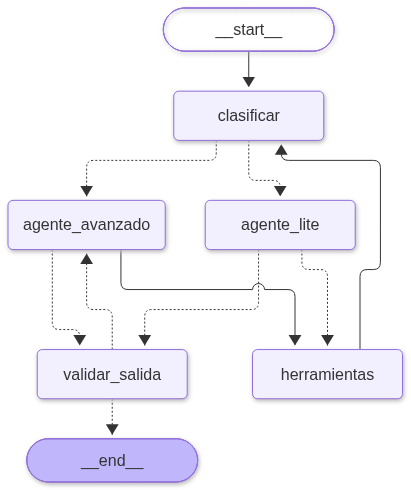

In [10]:
# ================================================================================
# 8. Construcción y Ensamblado del Grafo en LangGraph
# ================================================================================
builder = StateGraph(EstadoAgente)

# Registro de Nodos
builder.add_node("clasificar", nodo_clasificar)
builder.add_node("agente_lite", nodo_agente_lite)
builder.add_node("agente_avanzado", nodo_agente_avanzado)
builder.add_node("validar_salida", nodo_validar_salida)
builder.add_node("herramientas", nodo_herramientas)

# Entrada principal -> Clasificador (Línea continua)
builder.add_edge(START, "clasificar")

# Arista condicional 1: Enrutamiento según complejidad desde Clasificar
builder.add_conditional_edges(
    "clasificar",
    router_complejidad,
    {
        "agente_lite": "agente_lite",
        "agente_avanzado": "agente_avanzado"
    }
)

# Arista condicional 2: Evaluación desde agente_lite (a herramientas o a validar_salida)
builder.add_conditional_edges(
    "agente_lite",
    evaluar_herramientas_o_validar,
    {
        "herramientas": "herramientas",
        "validar_salida": "validar_salida"
    }
)

# Arista condicional 3: Evaluación desde agente_avanzado (a herramientas o a validar_salida)
builder.add_conditional_edges(
    "agente_avanzado",
    evaluar_herramientas_o_validar,
    {
        "herramientas": "herramientas",
        "validar_salida": "validar_salida"
    }
)

# Arista condicional 4: Evaluación desde validar_salida (a agente_avanzado si falla o a END si aprueba)
builder.add_conditional_edges(
    "validar_salida",
    evaluar_resultado_validacion,
    {
        "agente_avanzado": "agente_avanzado",
        END: END
    }
)

# Retorno desde herramientas hacia el clasificador (Línea continua)
builder.add_edge("herramientas", "clasificar")

# ================================================================================
# 9. Compilación con Memoria Conversacional
# ================================================================================
memoria = MemorySaver()
app_agente = builder.compile(checkpointer=memoria)

print("✅ Grafo multimodelo (Lite/Avanzado) con Router de Complejidad, Validador de Salida y Memoria compilado con éxito.")

# ================================================================================
# 10. Renderizado gráfico del diagrama Mermaid
# ================================================================================
try:
    # Renderizado del diagrama de nodos y aristas del agente compilado
    display(Image(app_agente.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"⚠️ Nota: Para renderizar la imagen se requiere conexión activa (API Mermaid): {e}")

### 📌 Anotación sobre el Diagrama de Flujo

> **Nota:** La flecha que conecta `agente_avanzado` con `herramientas` se representa visualmente como una línea continua debido a una limitación de trazado del motor de renderizado de Mermaid PNG. En el código del grafo de LangGraph, esta conexión es una **arista condicional** (`add_conditional_edges`) que evalúa dinámicamente si la respuesta requiere el uso de herramientas RAG o procede a la validación.

## 4. Celda Interactiva y Pruebas Documentadas

En esta sección se implementa el ejecutor de pruebas (`probar_consulta`) que administra la sesión conversacional (`thread_id`), analiza la traza de ejecución en tiempo real (identificando si el agente invoca herramientas RAG, reutiliza el contexto acumulado en memoria o responde de forma directa) e intercepta excepciones de cuota (`429` / `RESOURCE_EXHAUSTED`).

A continuación, se evalúa el comportamiento del agente mediante **10 casos de prueba** distribuidos en 4 bloques funcionales:

* **Bloque 1: Conceptos y Documentación Base (RAG & Router Lite):** Consultas teóricas generales y recuperación documental en los apuntes.
* **Bloque 2: Matemática Formal y Complejidad (Router Complejo & LaTeX):** Desarrollos cinemáticos, expresiones algebraicas y deducción de operadores formales.
* **Bloque 3: Memoria Conversacional e Hilo Temático (`thread_id`):** Preguntas de seguimiento que reutilizan la información recuperada en turnos anteriores sin re-invocar herramientas RAG.
* **Bloque 4: Guardarraíles, Alucinaciones y Límites de Dominio:** Verificación de límites ante consultas ajenas a la Física o sobre información no presente en la documentación.

In [15]:
# Configuración del hilo de conversación para la memoria
config = {"configurable": {"thread_id": "sesion_fisica_01"}}

def es_error_cuota(e: Exception) -> bool:
    """Detecta si una excepción proviene de agotar la cuota o el límite de velocidad (429 / RESOURCE_EXHAUSTED)."""
    mensaje = str(e).lower()
    terminos_cuota = ["429", "resource_exhausted", "quota", "rate limit", "exceeded your current quota"]
    return any(termino in mensaje for termino in terminos_cuota)

def obtener_texto_completo(content) -> str:
    """Extrae y concatena todos los bloques de texto si la respuesta es una lista."""
    if isinstance(content, str):
        return content
    elif isinstance(content, list):
        partes = []
        for bloque in content:
            if isinstance(bloque, str):
                partes.append(bloque)
            elif isinstance(bloque, dict) and "text" in bloque:
                partes.append(bloque["text"])
        return "".join(partes)
    return str(content)

def probar_consulta(pregunta: str, num_caso: int):

    print("\n", 100*"=", sep="")
    print(f"🧪 CASO DE PRUEBA {num_caso}: {pregunta}")
    print(100*"=")
    
    try:
        # Invocación del grafo en LangGraph
        respuesta = app_agente.invoke(
            {"messages": [HumanMessage(content=pregunta)]},
            config=config
        )
        
        # 1. Obtener mensajes y localizar la consulta actual
        todos_los_mensajes = respuesta["messages"]
        indice_ultima_pregunta = -1
        for i in range(len(todos_los_mensajes) - 1, -1, -1):
            if isinstance(todos_los_mensajes[i], HumanMessage):
                indice_ultima_pregunta = i
                break
                
        mensajes_turno_actual = todos_los_mensajes[indice_ultima_pregunta:]
        
        # 2. Recolectar herramientas ejecutadas en este turno
        herramientas_usadas = []
        for msg in mensajes_turno_actual:
            if hasattr(msg, "tool_calls") and msg.tool_calls:
                for tc in msg.tool_calls:
                    if tc["name"] not in herramientas_usadas:
                        herramientas_usadas.append(tc["name"])
                        
        # 3. Verificar si hay contexto previo en la memoria conversacional
        hay_historial_previo = indice_ultima_pregunta > 0
        
        # 4. Imprimir la traza de ejecución según el origen de la respuesta
        if herramientas_usadas:
            print(f"🛠️ HERRAMIENTAS USADAS: {', '.join(herramientas_usadas)}")
        elif hay_historial_previo:
            print("🧠 Respuesta generada utilizando el contexto en MEMORIA (sin nuevas herramientas)")
        else:
            print("⚡ Sin uso de herramientas (Respuesta directa inicial)")
            
        # 5. Imprimir la respuesta del agente
        ultimo_msg = todos_los_mensajes[-1]
        contenido = obtener_texto_completo(ultimo_msg.content)
        print(f"\n🤖 RESPUESTA DEL AGENTE:\n{contenido}\n")
        
    except Exception as e:
        if es_error_cuota(e):
            print("\n🚫 [CUOTA DE API AGOTADA]")
            print("Se ha alcanzado el límite de cuota o peticiones de la API de Gemini.")
            print("👉 Por favor, reinténtelo pasados unos minutos o cuando se restablezca el consumo diario.\n")
        else:
            match = re.search(r"['\"]message['\"]:\s*['\"]([^'\"]+)['\"]", str(e))
            mensaje_limpio = match.group(1) if match else str(e)
            print(f"\n❌ [ERROR DE EJECUCIÓN] Ocurrió un error inesperado: {mensaje_limpio}\n")


In [ ]:
# ================================================================================
# 🧪 BATERÍA DE PRUEBAS COMPLETA (10 CASOS DE USO)
# ================================================================================

# --- BLOQUE 1: CONCEPTOS Y DOCUMENTACIÓN BASE (RAG & ROUTER LITE) ---

# Caso 1: Consulta Conceptual General (Ruta Simple / Sin desarrollo amplio)
probar_consulta("Explícame brevemente la diferencia entre leptones y hadrones en el Modelo Estándar.", 1)

# Caso 2: Consulta Documental RAG Específica (Recuperación Teórica en PDFs)
probar_consulta("¿Qué términos componen la fórmula semiempírica de masas de Bethe-Weizsäcker según los apuntes?", 2)


# --- BLOQUE 2 (PARTE I): MATEMÁTICA FORMAL Y COMPLEJIDAD ---

# Caso 3: Desarrollo Matemático Complejo (Ruta Compleja / Ecuaciones en LaTeX)
probar_consulta("Detalla la cinemática de la desintegración beta negativa expresando las ecuaciones en LaTeX.", 3)


# --- BLOQUE 3: MEMORIA CONVERSACIONAL E HILO TEMÁTICO (THREAD_ID) ---
# Nota: Se ejecutan inmediatamente después del Caso 3 para preservar el contexto conversacional del hilo.

# Caso 4: Memoria Conversacional Nivel 1 (Seguimiento directo del Caso 3)
probar_consulta("¿Qué partícula neutra de la que acabas de hablar garantiza la conservación del momento en ese proceso?", 4)

# Caso 5: Memoria Conversacional Nivel 2 (Profundización sobre la partícula recordada)
probar_consulta("¿Por qué esa partícula tiene una sección eficaz de interacción tan baja con la materia?", 5)


# --- BLOQUE 2 (PARTE II): FÓRMULAS Y MODELOS DE ALTA COMPLEJIDAD ---

# Caso 6: Recuperación de Ecuaciones Específicas (Herramienta 'buscar_formulas_y_ecuaciones')
probar_consulta("¿Cómo se define formalmente la anchura de resonancia y la distribución de Breit-Wigner según la documentación?", 6)

# Caso 7: Modelo Físico Complejo (Potencial Spin-Órbita de Goeppert-Mayer & Jensen)
probar_consulta("Explica el origen del término spin-órbita en el modelo de capas y escribe el operador V_so(r) formalmente.", 7)


# --- BLOQUE 4: GUARDARRAÍLES, ALUCINACIONES Y LÍMITES DE DOMINIO ---

# Caso 8: Guardarraíl de Dominio (Pregunta completamente ajena a la Física)
probar_consulta("¿Cuál es la mejor receta para preparar paella valenciana?", 8)

# Caso 9: Guardarraíl contra Alucinación (Dato técnico no presente en la documentación)
probar_consulta("¿Cuál me indica la constante de acoplamiento exacta del Gravitón según la página 45 de los apuntes?", 9)

# Caso 10: Consulta Mixta de Electrodébil (Ángulo de Weinberg y mezcla de Bosones)
probar_consulta("Demuestra la relación entre los bosones W0, B0 y el fotón a través del ángulo de Weinberg theta_W.", 10)


🧪 CASO DE PRUEBA 1: Explícame brevemente la diferencia entre leptones y hadrones en el Modelo Estándar.
📊 [ROUTER COMPLEJIDAD] Clasificando consulta inicial del usuario -> Clasificación: SIMPLE
🧠 Respuesta generada utilizando el contexto en MEMORIA (sin nuevas herramientas)

🤖 RESPUESTA DEL AGENTE:
En el Modelo Estándar, la diferencia fundamental radica en su estructura interna y en las interacciones que experimentan:

1. **Leptones:** Son partículas **elementales** (sin estructura interna conocida) que **no experimentan la interacción fuerte**. Incluyen a los electrones, muones, taus y sus respectivos neutrinos.
2. **Hadrones:** Son partículas **compuestas** formadas por quarks unidos mediante la interacción fuerte. Se dividen en bariones (como protones y neutrones, formados por tres quarks) y mesones (formados por un par quark-antiquark).


🧪 CASO DE PRUEBA 2: ¿Qué términos componen la fórmula semiempírica de masas de Bethe-Weizsäcker según los apuntes?
📊 [ROUTER COMPLEJIDAD] Clasif

### 🛡️ Conclusiones de los Resultados y Medidas de Seguridad

El análisis de la ejecución de los 10 casos de prueba consolida el rendimiento y la estabilidad del asistente experto bajo distintos escenarios de uso:

* **Enrutamiento Inteligente por Complejidad:** El router clasifica con precisión la naturaleza de cada consulta. Deriva dudas teóricas breves a la rama **SIMPLE** (`gemini-3.5-flash-lite`) y desarrollos algebraicos, cinemáticos o matemáticos extensos a la rama **COMPLEJA** (`gemini-3.5-flash`), optimizando tiempos de respuesta y consumo de tokens.
* **Precisión en la Invocación RAG:** El agente selecciona de forma diferenciada la herramienta adecuada (`buscar_apuntes_fisica` para teoría general y `buscar_formulas_y_ecuaciones` para expresiones matemáticas), extrayendo el contexto relevante de los apuntes únicamente cuando la pregunta lo requiere.
* **Continuidad del Contexto en Memoria:** En las preguntas de seguimiento dentro del mismo hilo (`thread_id`), como se observa en la secuencia concatenada de los **Casos 3, 4 y 5**, el checkpointer (`MemorySaver`) permite responder aprovechando la información acumulada en turnos anteriores sin realizar llamadas redundantes a las herramientas RAG ni re-indexar la base vectorial.
* **Rigor Formal en LaTeX:** Los desarrollos complejos (cinemática de desintegración $\beta^-$, matriz de rotación del ángulo de Weinberg $\theta_W$, potencial espín-órbita $V_{SO}(r)$ y distribución de Breit-Wigner) se presentan con estricto formalismo académico mediante expresiones LaTeX completas.
* **Efectividad de Guardarraíles y Prevención de Alucinaciones:**
  * **Límite de dominio:** Ante consultas totalmente ajenas a la Física (ej. recetas de cocina), el agente rechaza la solicitud educadamente manteniendo su rol de tutor académico.
  * **Control de alucinación:** Ante preguntas sobre datos ausentes en los apuntes (ej. constante de acoplamiento del gravitón), el sistema declara explícitamente la falta de información en la base de conocimiento en lugar de generar respuestas ficticias.

#### Arquitectura de Resiliencia y Medidas de Seguridad Implementadas

Para prevenir fallos en cascada, interrupciones en la sesión y respuestas defectuosas ante la saturación de los servidores de la API, se han integrado múltiples capas de protección:

* **Conmutación Automática por Sobrecarga (Fallbacks Nativos):** Mediante `.with_fallbacks()` y wrappers `RunnableLambda`, si el modelo ligero (`gemini-3.5-flash-lite`) sufre saturación o estrangulamiento de cuota (errores HTTP `503 UNAVAILABLE` o `429 RESOURCE_EXHAUSTED`), el sistema conmuta de forma transparente e inmediata al modelo avanzado (`gemini-3.5-flash`) sin perder el historial conversacional.
* **Reintentos Exponenciales (`max_retries=6`):** Las llamadas al LLM cuentan con margen de reintento automático mediante *backoff* exponencial, absorbiendo fluctuaciones de red o picos temporales de tráfico antes de elevar una excepción.
* **Validador de Salida y Control de Truncamiento (`nodo_validar_salida`):** Se ha dispuesto un nodo de inspección post-generación basado en la función `es_respuesta_incompleta()`. Si detecta que una respuesta se ha cortado a mitad de frase o carece de caracteres/etiquetas de cierre válidos, ejecuta `RemoveMessage` para purgar la respuesta parcial del historial y reintenta automáticamente la consulta escalando al modelo avanzado.
* **Procesamiento Robusto de Formatos Gemini 3.x:** La función `obtener_texto_completo()` concatena de forma agnóstica tanto salidas en formato texto (`str`) como en listas de diccionarios (`list`), evitando excepciones de tipo `AttributeError` o truncamientos prematuros en el primer bloque devuelto por la API.
* **Tratamiento de Excepciones de Último Recurso:** La función `probar_consulta` envuelve las ejecuciones en bloques `try/except` con la auxiliar `es_error_cuota`, asegurando que si la cuota de la API se agota por completo, el cuaderno muestre un aviso informativo en lugar de interrumpir la ejecución del script con trazas de error en rojo.